# ST1519 Agile MLOps CA1 ? PBI 02: Extra Trees Fraud Model
**Developer:** Chu ? **Runs:** `extra_trees_chu_safe` and `extra_trees_chu_full`

## 1. Model Objective
Predict `is_fraud = 1` for future SP-buy orders. The Trust & Safety team needs precise alerts while retaining useful fraud recall. Compare Safe features with Full features to investigate uncertain customer snapshots. Safe is the production candidate; Full is exploratory.

## 2. Algorithm Explanation and Justification
Extra Trees averages the fraud probabilities from many randomized decision trees. Each tree considers a random subset of features and randomized split thresholds, then selects a split using impurity reduction. With the default `bootstrap=False`, each tree uses all training rows.

- **Nonlinear relationships:** trees capture interactions among order, payment and customer attributes.
- **No scaling required:** inputs are already numeric; trees compare feature values with thresholds.
- **Reduced variance:** averaging many randomized trees reduces the instability of a single tree.
- **Parallel training:** trees can train across CPU cores using `n_jobs=-1`.
- **Limitations:** the ensemble is less interpretable than one tree and may use more memory and training time. Deep trees can overfit. Impurity importance can favor features with more possible split points.

Depth and minimum leaf size control complexity. Balanced class weights are compared with unweighted training rather than assumed to be better. Training speed must be measured on this machine.

## 3. Imports and Configuration
Reusable training and tuning live in `src/extra_trees_chu.py`; the notebook uses the team's loading, evaluation and MLflow helpers. This notebook explicitly uses local SQLite tracking for development. It does not upload runs to AWS.

Use the project `.venv` kernel. Install dependencies from `requirements.txt` if needed. `RUN_SEARCH=False` reuses the configuration saved by a previous search; it does not silently fall back to untuned defaults.

In [1]:
import os
import sys
import json
import time
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "src" / "extra_trees_chu.py").is_file())
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))
os.environ["MLFLOW_DISABLE_AGENT_HINT"] = "1"

import numpy as np
import pandas as pd
import model_utils as mu
import extra_trees_chu as et
import mlflow
import mlflow.sklearn
from mlflow_utils import log_trained_model
from data_processing import SNAPSHOT_FEATURES
from data_split import create_split_labels, TRAIN_END, VAL_END
from IPython.display import Image, Markdown, display
import matplotlib.pyplot as plt
%matplotlib inline

DATA_DIR = Path(os.environ.get("FRAUD_DATA_DIR", ROOT / "data" / "processed"))
OUTPUT_DIR = ROOT / "outputs"
EXPERIMENT = "SP-buy-Fraud-Detection"
DEVELOPER = "chu"
RUN_SEARCH = True
LOG_TO_MLFLOW = True
SEARCH_DIR = OUTPUT_DIR / et.SHORT_NAME
SEARCH_DIR.mkdir(parents=True, exist_ok=True)
workflow_started = time.perf_counter()

pd.set_option("display.float_format", "{:.4f}".format)
print("Repository:", ROOT)
print("Python:", sys.executable)
print("Random seed:", mu.RANDOM_SEED)

Repository: C:\Users\User\Desktop\AMLOPs\CA1\MLOps_CA1_group5
Python: C:\Users\User\Desktop\AMLOPs\CA1\MLOps_CA1_group5\.venv\Scripts\python.exe
Random seed: 42


## 4. Dataset Loading and Validation
Load the processed Safe and Full CSVs. Shared validation checks required metadata, binary labels, unique `(country_code, order_id)` keys, and finite numeric features. SHA-256 checksums identify the exact inputs. Both datasets must contain identical orders and labels in the same order.

In [2]:
safe_path = mu.dataset_path("safe", DATA_DIR)
full_path = mu.dataset_path("full", DATA_DIR)
df_safe = mu.load_feature_data(safe_path)
df_full = mu.load_feature_data(full_path)
mu.check_same_orders(df_safe, df_full)
checksums = {"safe": mu.file_sha256(safe_path), "full": mu.file_sha256(full_path)}
display(pd.DataFrame({
    "Rows": [len(df_safe), len(df_full)],
    "Features": [len(mu.get_feature_columns(df_safe)), len(mu.get_feature_columns(df_full))],
    "Fraud rate (%)": [100 * df_safe.is_fraud.mean(), 100 * df_full.is_fraud.mean()],
    "SHA256": [checksums["safe"], checksums["full"]],
}, index=["Safe", "Full"]))

,Rows,Features,Fraud rate (%),SHA256
Safe,949872,31,10.9933,656a05ca11891816989d51eeaf4c706aab2e9b38682fdf...
Full,949872,41,10.9933,d5abc1ac0ce107b1118a47327965b2ba1393f917a59b4f...


## 5. Feature Selection
Identifiers, raw `country_code`, order dates and the target are excluded from model inputs. Country information remains through numeric one-hot columns. `refund_value` is forbidden because it can expose information recorded after the fraud decision.

Full adds the team's uncertain customer-snapshot features. Their availability at order time has not been established, so they remain excluded from the production candidate.

In [3]:
safe_features = mu.get_feature_columns(df_safe)
full_features = mu.get_feature_columns(df_full)
extra_features = sorted(set(full_features) - set(safe_features))
assert set(safe_features).issubset(full_features)
assert set(extra_features) == set(SNAPSHOT_FEATURES)
assert "refund_value" not in safe_features + full_features
print("Safe feature count:", len(safe_features))
print("Full feature count:", len(full_features))
print("Excluded snapshot features:")
for feature in extra_features:
    print("-", feature)

Safe feature count: 31
Full feature count: 41
Excluded snapshot features:
- associated_capped
- avg_payment_per_order
- cancel_rate
- log_num_associated_customers
- log_num_cancelled_orders_last_50days
- log_num_orders_last_50days
- log_num_refund_orders_last_50days
- log_total_payment_last_50days
- mobile_verified
- refund_rate


## 6. Shared Chronological Split
The shared split uses training orders up to **15 March 2023**, validation from **16 March to 13 April**, and testing from **14 April onwards**. Training fits the model; validation selects settings and the threshold; test provides final evaluation. Chronological boundaries simulate predicting later orders without fitting on future observations.

In [4]:
split = create_split_labels(df_safe)
assert split.equals(create_split_labels(df_full))
split_summary = (df_safe.assign(split=split).groupby("split").agg(
    first_date=("order_date", "min"), last_date=("order_date", "max"),
    orders=("is_fraud", "size"), fraud_orders=("is_fraud", "sum"),
    fraud_rate=("is_fraud", "mean"),
).loc[["Train", "Validation", "Test"]])
split_summary["share_%"] = 100 * split_summary["orders"] / len(df_safe)
display(split_summary)

,first_date,last_date,orders,fraud_orders,fraud_rate,share_%
split,,,,,,
Train,2022-11-12,2023-03-15,665876,67594,0.1015,70.1017
Validation,2023-03-16,2023-04-13,139874,18993,0.1358,14.7256
Test,2023-04-14,2023-05-11,144122,17835,0.1237,15.1728


## 7. Class Imbalance Analysis
Accuracy can be high even when a model misses all fraud. Report fraud precision and recall, alongside F1, average precision (AP) and ROC-AUC. AP summarizes the precision-recall curve and depends on class prevalence, so comparisons across periods require care.

,orders,percent
is_fraud,,
0,845450,89.0100
1,104422,10.9900


Train: 665,876 orders | fraud 10.15% | always-nonfraud accuracy 89.85%
Validation: 139,874 orders | fraud 13.58% | always-nonfraud accuracy 86.42%
Test: 144,122 orders | fraud 12.37% | always-nonfraud accuracy 87.63%


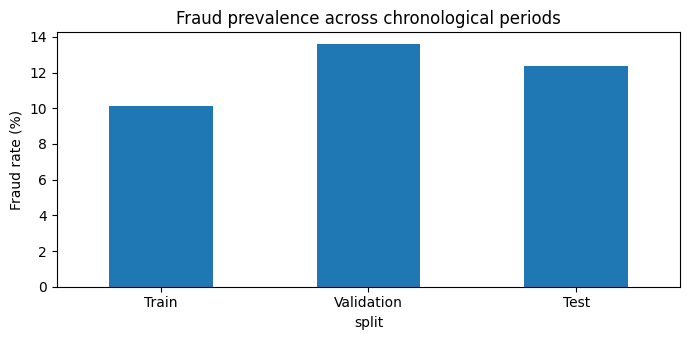

In [5]:
display(mu.class_balance(df_safe["is_fraud"]))
for name in ["Train", "Validation", "Test"]:
    y = df_safe.loc[split == name, "is_fraud"]
    print(f"{name}: {len(y):,} orders | fraud {y.mean():.2%} | "
          f"always-nonfraud accuracy {1-y.mean():.2%}")
ax = split_summary["fraud_rate"].mul(100).plot.bar(rot=0, figsize=(7, 3.5))
ax.set_ylabel("Fraud rate (%)")
ax.set_title("Fraud prevalence across chronological periods")
plt.tight_layout()
plt.show()

## 8. Local MLflow and Serialization Smoke Test
Use the shared experiment and logging helpers. Before expensive training, fit a small development model, log it with `skops`, reload it, and compare predicted probabilities. Explicitly trust only the scikit-learn tree type needed by this model. Smoke results are not final evaluation scores.

In [6]:
local_folder = (ROOT / "mlruns").resolve()
local_folder.mkdir(exist_ok=True)
local_uri = f"sqlite:///{(local_folder / 'mlflow.db').as_posix()}"
os.environ["MLFLOW_TRACKING_URI"] = local_uri
mlflow_location = mu.setup_mlflow(EXPERIMENT, local_uri) if LOG_TO_MLFLOW else None
if LOG_TO_MLFLOW:
    assert mlflow.get_tracking_uri() == local_uri
    assert mlflow_location == "local"

smoke_parts, _ = mu.split_data(df_safe, sample_frac=0.02)
X_train_smoke, y_train_smoke = smoke_parts["Train"]
X_val_smoke, y_val_smoke = smoke_parts["Validation"]
smoke_model, _ = et.train_model(
    X_train_smoke, y_train_smoke, X_val_smoke, y_val_smoke,
    {**et.DEFAULT_PARAMS, "n_estimators": 20, "max_depth": 8},
)
X_sample = X_val_smoke.head(100).copy()
if LOG_TO_MLFLOW:
    with mlflow.start_run(run_name="chu_extra_trees_safe_smoke_v1"):
        mlflow.set_tags({"run_type": "smoke", "production_eligible": "false",
                         "team_member": DEVELOPER, "tracking_location": "local"})
        model_info = log_trained_model(
            smoke_model, X_sample, model_name="extra_trees_smoke",
            skops_trusted_types=et.TRUSTED_TYPES,
        )
        reloaded_smoke = mlflow.sklearn.load_model(model_info.model_uri)
        np.testing.assert_allclose(smoke_model.predict_proba(X_sample),
                                   reloaded_smoke.predict_proba(X_sample), rtol=1e-7, atol=1e-9)
        print("Serialization passed:", model_info.model_uri)
    del reloaded_smoke
else:
    print("MLflow disabled; serialization test skipped.")
del smoke_parts, X_train_smoke, y_train_smoke, X_val_smoke, y_val_smoke, smoke_model
print("Smoke training passed.")

[MLflow] No shared server configured -> LOCAL testing store: sqlite:///C:/Users/User/Desktop/AMLOPs/CA1/MLOps_CA1_group5/mlruns/mlflow.db


Serialization passed: models:/m-d64d0ca2b89845b485e6d0dc2b9cfef5
Smoke training passed.


## 9. Hyperparameter Selection
Search **eight configurations** using all Safe training and validation orders. No test scores enter the search. The original default configuration is included.

| Parameter | Values | Purpose |
|---|---|---|
| `max_depth` | 15, 25 | Compare moderate and deeper trees |
| `min_samples_leaf` | 5, 25 | Compare flexible leaves with stronger regularization |
| `class_weight` | None, balanced | Check whether minority-class weighting helps |
| `n_estimators` | 100, fixed | Limit search cost while averaging many trees |
| `max_features` | sqrt, fixed | Random feature subsets diversify trees |
| `min_samples_split` | 10, fixed | Prevent very small splits |
| `random_state` | 42 | Reproducibility |

Rank by **validation AP**, a threshold-independent measure suited to imbalanced detection, matching the team's search approach. Precision and recall remain the operational reporting priorities. 'Best' means the best validation AP among these eight candidates, not a global optimum.

In [7]:
search_started = time.perf_counter()
if RUN_SEARCH:
    tuning_table, params = et.tune(df_safe)
    tuning_table.to_csv(SEARCH_DIR / "tuning_results.csv", index=False)
    (SEARCH_DIR / "selected_params.json").write_text(json.dumps(params, indent=2), encoding="utf-8")
    if LOG_TO_MLFLOW:
        mu.log_tuning_table(tuning_table, "extra_trees_tuning", experiment=EXPERIMENT,
                            tracking_uri=local_uri, developer=DEVELOPER)
else:
    params = et.load_selected_params(SEARCH_DIR / "selected_params.json")
    tuning_table = pd.read_csv(SEARCH_DIR / "tuning_results.csv")
search_seconds = time.perf_counter() - search_started
display(tuning_table)
print("Selected settings:", params)
print(f"Search and logging: {search_seconds:.1f}s")
display(Markdown(
    f"**Search interpretation:** the selected candidate achieved validation AP "
    f"**{tuning_table.iloc[0]['val_average_precision']:.4f}**. "
    f"Its depth limit is **{params['max_depth']}**, minimum leaf size **{params['min_samples_leaf']}**, "
    f"and class weighting **{params['class_weight']}**. "
    "Training AP is shown as an overfitting diagnostic; it is not the selection metric. "
    "Differences in train and validation prevalence also affect AP."
))

Candidate 1/8 | validation AP 0.52856 | fit 11.1s | depth=15 leaf=5 weight=None


Candidate 2/8 | validation AP 0.51345 | fit 8.9s | depth=15 leaf=25 weight=None


Candidate 3/8 | validation AP 0.53322 | fit 11.7s | depth=25 leaf=5 weight=None


Candidate 4/8 | validation AP 0.51723 | fit 9.7s | depth=25 leaf=25 weight=None


Candidate 5/8 | validation AP 0.51360 | fit 11.6s | depth=15 leaf=5 weight=balanced


Candidate 6/8 | validation AP 0.49807 | fit 10.3s | depth=15 leaf=25 weight=balanced


... (2 outputs left out)

[MLflow] No shared server configured -> LOCAL testing store: sqlite:///C:/Users/User/Desktop/AMLOPs/CA1/MLOps_CA1_group5/mlruns/mlflow.db


,candidate,n_estimators,max_depth,min_samples_split,min_samples_leaf,max_features,class_weight,random_state,n_jobs,val_average_precision,val_roc_auc,train_average_precision,train_seconds
0,2,100,25,10,5,sqrt,None,42,-1,0.5332,0.8537,0.4587,11.7252
1,6,100,25,10,5,sqrt,balanced,42,-1,0.5298,0.8525,0.4306,13.8491
2,0,100,15,10,5,sqrt,None,42,-1,0.5286,0.8498,0.3942,11.1431
3,3,100,25,10,25,sqrt,None,42,-1,0.5172,0.8475,0.3686,9.7271
4,4,100,15,10,5,sqrt,balanced,42,-1,0.5136,0.8473,0.3561,11.6240
5,1,100,15,10,25,sqrt,None,42,-1,0.5135,0.8450,0.3485,8.9361
6,7,100,25,10,25,sqrt,balanced,42,-1,0.5064,0.8439,0.3394,10.8755
7,5,100,15,10,25,sqrt,balanced,42,-1,0.4981,0.8391,0.3256,10.3077


Selected settings: {'n_estimators': 100, 'max_depth': 25, 'min_samples_split': 10, 'min_samples_leaf': 5, 'max_features': 'sqrt', 'class_weight': None, 'random_state': 42, 'n_jobs': -1}
Search and logging: 96.4s


**Search interpretation:** the selected candidate achieved validation AP **0.5332**. Its depth limit is **25**, minimum leaf size **5**, and class weighting **None**. Training AP is shown as an overfitting diagnostic; it is not the selection metric. Differences in train and validation prevalence also affect AP.

## 10. Safe Dataset Training
Train using the selected configuration. The shared pipeline chooses the probability threshold maximizing fraud F1 on Safe validation, then evaluates test performance and logs artifacts. This balances precision and recall; a deployment requiring a specific alert precision needs an agreed validation-based threshold policy.

In [8]:
production_started = time.perf_counter()
common = dict(output_dir=OUTPUT_DIR, mlflow_location=mlflow_location,
              developer=DEVELOPER, snapshot_features=SNAPSHOT_FEATURES,
              trusted_types=et.TRUSTED_TYPES)
result_safe, model_safe = mu.run_training(
    et.ALGORITHM, et.SHORT_NAME, "safe", df_safe, et.train_model, params,
    et.feature_importance, dataset_sha256=checksums["safe"], **common,
)
safe_pipeline_seconds = time.perf_counter() - production_started
print(f"Safe threshold: {result_safe['threshold']:.5f}")
print(f"Safe fit time: {result_safe['train_seconds']:.2f}s")
print(f"Safe pipeline (split/train/evaluate/save/log): {safe_pipeline_seconds:.2f}s")

Safe threshold: 0.19306
Safe fit time: 11.93s
Safe pipeline (split/train/evaluate/save/log): 20.36s


## 11. Full Dataset Training
Use identical settings, chronological orders, seed and the **Safe threshold**. The feature set changes, enabling an exploratory comparison. The Full run is tagged as ineligible for production.

In [9]:
result_full, model_full = mu.run_training(
    et.ALGORITHM, et.SHORT_NAME, "full", df_full, et.train_model, params,
    et.feature_importance, threshold=result_safe["threshold"],
    dataset_sha256=checksums["full"], **common,
)
assert result_full["threshold"] == result_safe["threshold"]
results = [result_safe, result_full]
print(f"Full fit time: {result_full['train_seconds']:.2f}s")

Full fit time: 18.50s


## 12. Model Evaluation
Precision describes the fraud share among alerts; recall describes the fraction of fraud caught. F1 summarizes their balance. AP and ROC-AUC evaluate probability ranking. Confusion matrices show the operational counts of false alarms and missed fraud.

,extra_trees_chu_safe,extra_trees_chu_full
Accuracy,0.8369,0.8355
Precision (fraud),0.3966,0.4078
Recall (fraud),0.6105,0.7286
F1 (fraud),0.4808,0.5229
Average precision,0.4339,0.4955
ROC-AUC,0.8078,0.8661
TP,10888,12995
FP,16566,18869
FN,6947,4840
TN,109721,107418


,dataset,split,threshold,accuracy,precision,recall,f1,roc_auc,average_precision,tp,tn,fp,fn
0,safe,validation,0.1931,0.8616,0.4924,0.6204,0.5491,0.8537,0.5332,11784,108733,12148,7209
1,safe,test,0.1931,0.8369,0.3966,0.6105,0.4808,0.8078,0.4339,10888,109721,16566,6947
2,full,validation,0.1931,0.8674,0.5086,0.6921,0.5864,0.8955,0.5762,13146,108182,12699,5847
3,full,test,0.1931,0.8355,0.4078,0.7286,0.5229,0.8661,0.4955,12995,107418,18869,4840


extra_trees_chu_safe


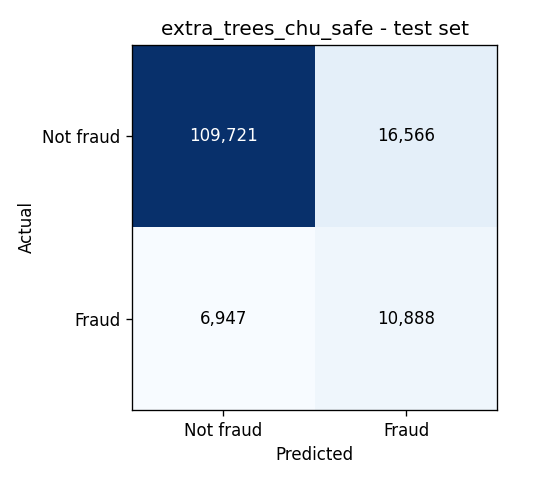

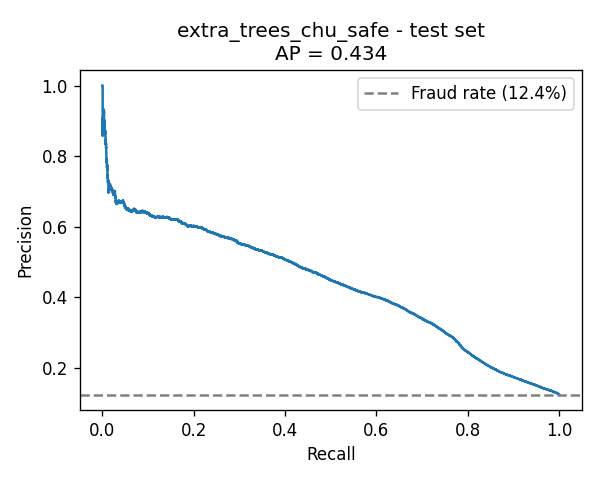

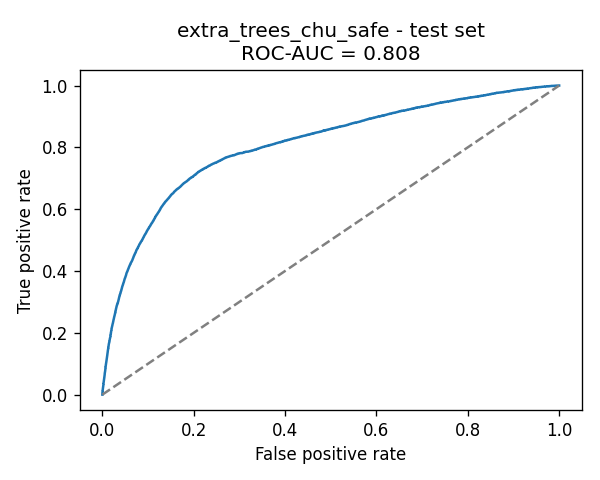

extra_trees_chu_full


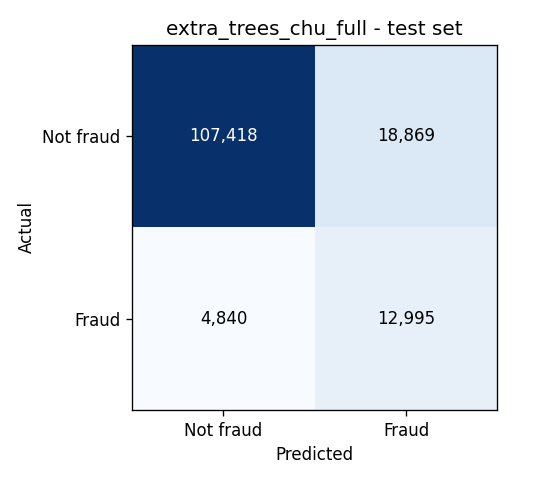

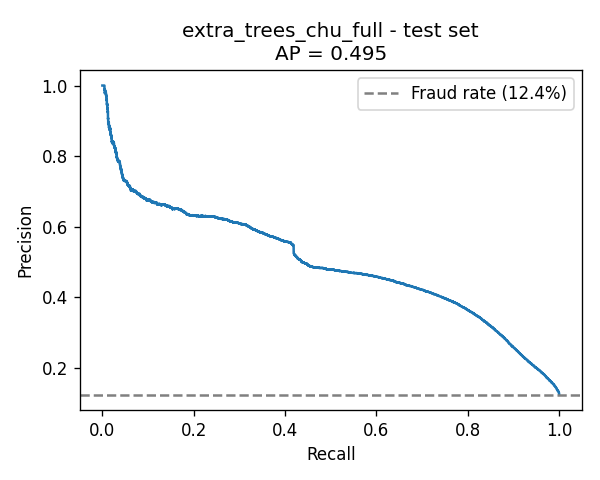

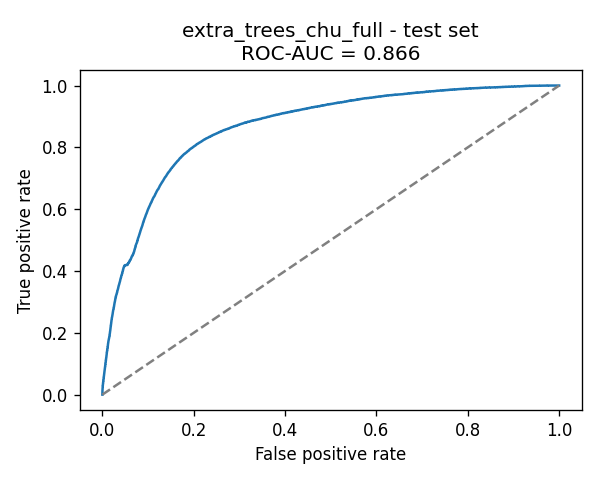

In [10]:
comparison = mu.comparison_table(results)
display(comparison)
comparison.to_csv(SEARCH_DIR / "comparison.csv")
metrics_rows = []
for result in results:
    for period in ["validation", "test"]:
        metrics_rows.append({"dataset": result["dataset_type"], "split": period,
                             "threshold": result["threshold"], **result[period]})
metrics_df = pd.DataFrame(metrics_rows)
display(metrics_df)
metrics_df.to_csv(SEARCH_DIR / "metrics.csv", index=False)
for result in results:
    print(result["run_name"])
    plots = OUTPUT_DIR / result["run_name"] / "plots"
    for filename in ["confusion_matrix_test.png", "precision_recall_test.png", "roc_test.png"]:
        display(Image(filename=str(plots / filename)))

## 13. Safe versus Full Comparison
The same threshold controls the comparison, although each model's probability calibration can differ. Full results are exploratory and must not influence selection of the production Safe configuration.

,extra_trees_chu_safe,extra_trees_chu_full,Full minus Safe
Precision (fraud),0.3966,0.4078,0.0112
Recall (fraud),0.6105,0.7286,0.1181
F1 (fraud),0.4808,0.5229,0.0421
Average precision,0.4339,0.4955,0.0616
ROC-AUC,0.8078,0.8661,0.0583


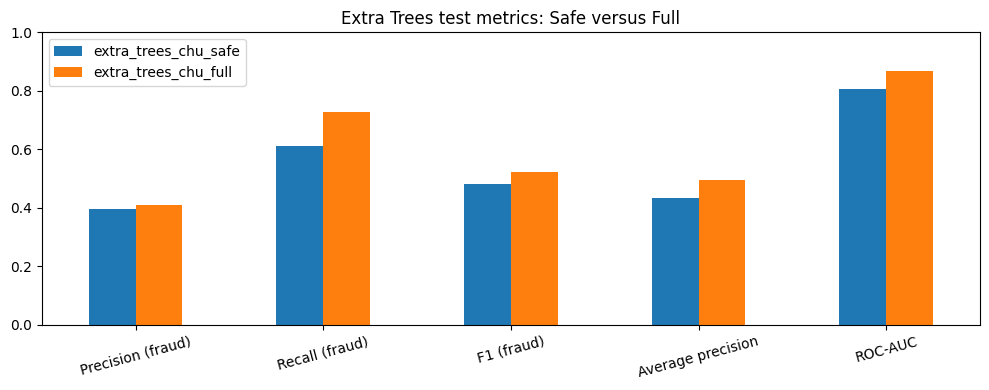

In [11]:
metric_names = ["Precision (fraud)", "Recall (fraud)", "F1 (fraud)", "Average precision", "ROC-AUC"]
difference = comparison.loc[metric_names].astype(float).copy()
difference["Full minus Safe"] = difference.iloc[:, 1] - difference.iloc[:, 0]
display(difference)
ax = comparison.loc[metric_names].astype(float).plot.bar(figsize=(10, 4), rot=15)
ax.set_ylim(0, 1)
ax.set_title("Extra Trees test metrics: Safe versus Full")
plt.tight_layout()
plt.show()

## 14. Potential Data Leakage Analysis
A Full-model advantage does not prove leakage. Compare monthly AP after the training cutoff to see when snapshot features help. A growing advantage near a possible snapshot date is consistent with temporal leakage, but changes in fraud patterns are another explanation. Feature provenance and availability at order time are needed to establish leakage.

,month,orders,fraud_rate_%,safe_AP,full_AP,gain_full_minus_safe
0,2023-03,77691,13.9400,0.5528,0.5870,0.0342
1,2023-04,148855,12.6100,0.4549,0.5078,0.0529
2,2023-05,57450,12.5700,0.4551,0.5218,0.0667


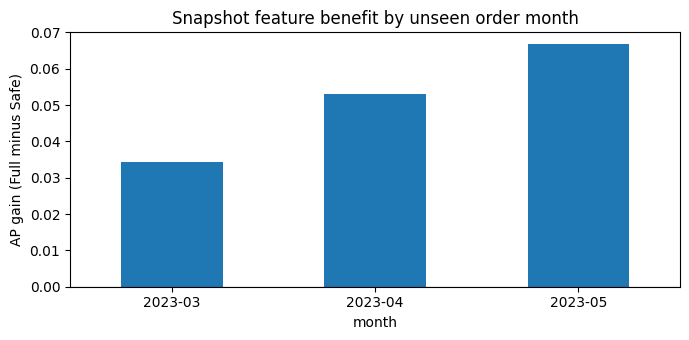

**Observed monthly AP differences:** 2023-03: +0.0342; 2023-04: +0.0529; 2023-05: +0.0667. These differences describe this run; they do not independently establish leakage. Snapshot features remain excluded from the production candidate.

In [12]:
by_month = mu.gain_by_month(model_safe, model_full, df_safe, df_full)
display(by_month)
by_month.to_csv(SEARCH_DIR / "monthly_comparison.csv", index=False)
ax = by_month.plot(x="month", y="gain_full_minus_safe", kind="bar", legend=False,
                   rot=0, figsize=(7, 3.5))
ax.axhline(0, color="black", linewidth=0.8)
ax.set_ylabel("AP gain (Full minus Safe)")
ax.set_title("Snapshot feature benefit by unseen order month")
plt.tight_layout()
plt.show()
monthly_text = "; ".join(f"{r.month}: {r.gain_full_minus_safe:+.4f}" for r in by_month.itertuples())
display(Markdown(f"**Observed monthly AP differences:** {monthly_text}. "
                 "These differences describe this run; they do not independently establish leakage. "
                 "Snapshot features remain excluded from the production candidate."))

## 15. Feature Importance
Built-in importance measures each feature's contribution to impurity reduction, averaged across trees. Red bars mark snapshot features. These values show reliance, not causality, and can be biased by feature cardinality and correlated predictors.

The first levels of one constituent Safe tree illustrate individual rules; that tree is only one component of the ensemble.

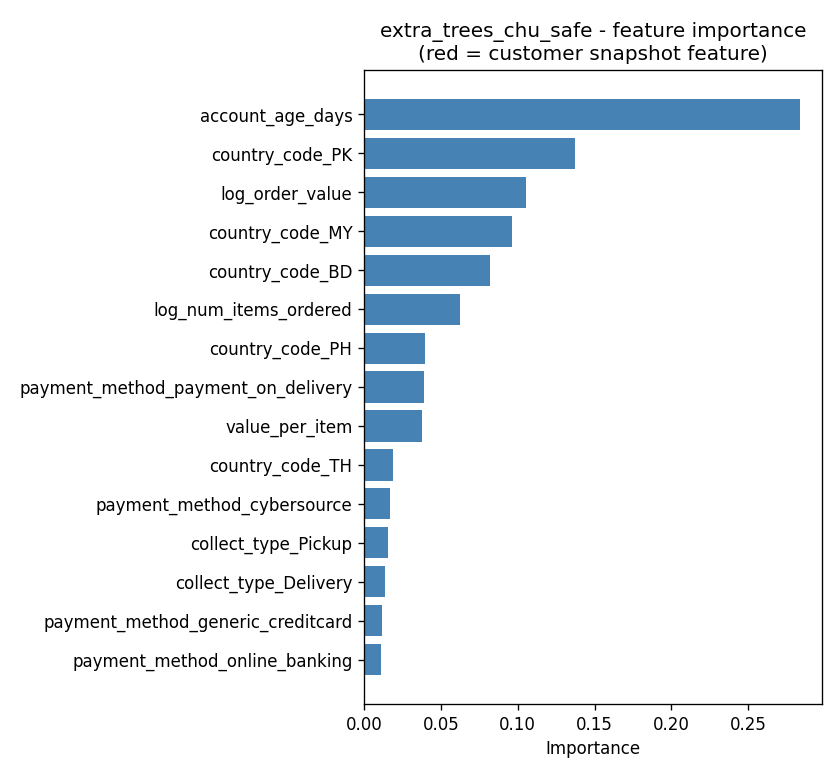

,feature,importance
0,account_age_days,0.2838
1,country_code_PK,0.1375
2,log_order_value,0.1055
3,country_code_MY,0.0962
4,country_code_BD,0.0817
5,log_num_items_ordered,0.0625
6,country_code_PH,0.0396
7,payment_method_payment_on_delivery,0.0390
8,value_per_item,0.0376
9,country_code_TH,0.0190


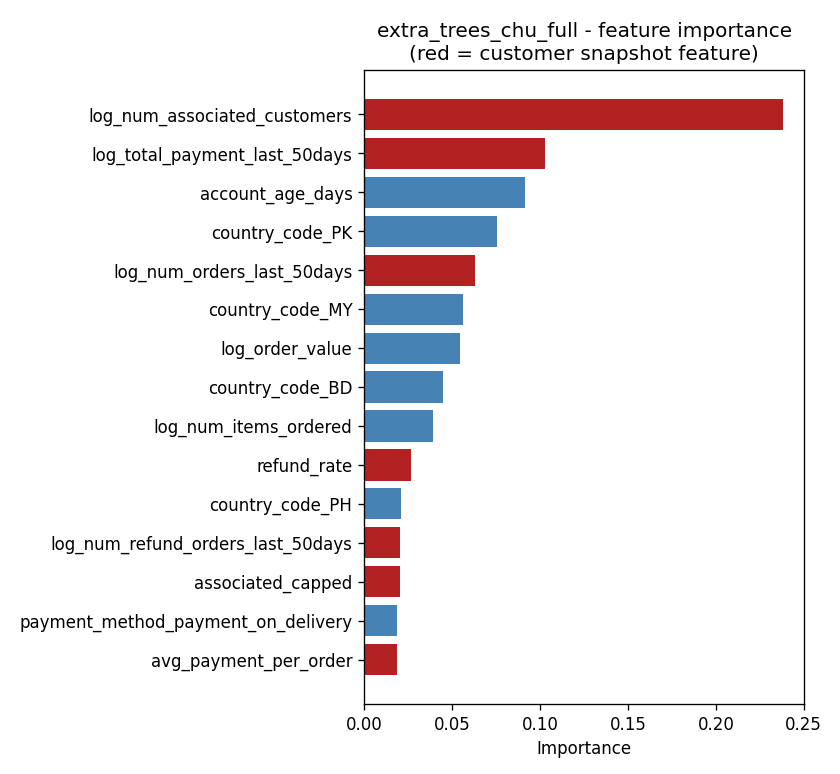

,feature,importance
0,log_num_associated_customers,0.2383
1,log_total_payment_last_50days,0.1027
2,account_age_days,0.0914
3,country_code_PK,0.0755
4,log_num_orders_last_50days,0.0633
5,country_code_MY,0.0563
6,log_order_value,0.0543
7,country_code_BD,0.0449
8,log_num_items_ordered,0.0389
9,refund_rate,0.0268


Full impurity importance from snapshot features: 52.1%


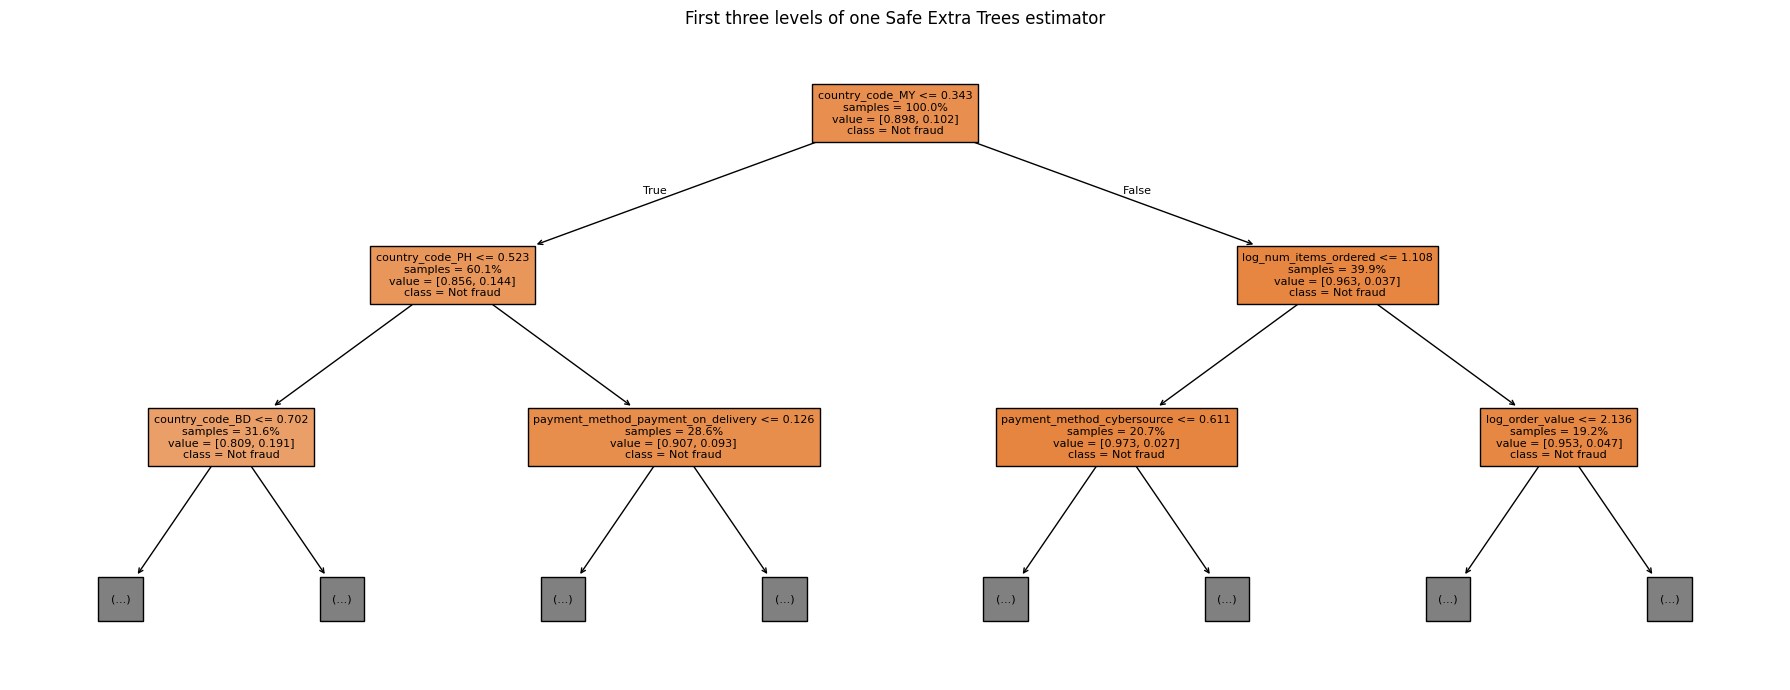

In [13]:
for result in results:
    display(Image(filename=str(OUTPUT_DIR / result["run_name"] / "plots" / "feature_importance.png")))
    display(result["importance"].head(15))
snapshot_share = result_full["importance"].loc[
    result_full["importance"]["feature"].isin(SNAPSHOT_FEATURES), "importance"
].sum()
print(f"Full impurity importance from snapshot features: {snapshot_share:.1%}")

from sklearn.tree import plot_tree
fig, ax = plt.subplots(figsize=(18, 7))
plot_tree(model_safe.estimators_[0], max_depth=2, feature_names=safe_features,
          class_names=["Not fraud", "Fraud"], filled=True, proportion=True,
          impurity=False, fontsize=8, ax=ax)
ax.set_title("First three levels of one Safe Extra Trees estimator")
plt.tight_layout()
plt.show()

## 16. MLflow Tracking and Full-Model Reload Verification
Team experiment: `SP-buy-Fraud-Detection`. Run names: `{member}_{algorithm}_{dataset_version}_{model_version}`. Validation/test metrics, dataset hashes, thresholds, feature metadata, plots and signed models are logged locally. `pr_auc` in MLflow is average precision.

Reload both final models and compare probabilities on their validation inputs, verifying ensemble serialization beyond the smoke test. Model probabilities must be paired with the saved decision threshold when serving predictions.

In [14]:
from mlflow.tracking import MlflowClient
client = MlflowClient() if LOG_TO_MLFLOW else None
for result, model, frame in [(result_safe, model_safe, df_safe), (result_full, model_full, df_full)]:
    if LOG_TO_MLFLOW:
        run = client.get_run(result["mlflow_run_id"])
        model_uri = run.data.tags["logged_model_uri"]
        restored = mlflow.sklearn.load_model(model_uri)
        sample = frame.loc[split == "Validation", result["features"]].head(100).astype("float32")
        np.testing.assert_allclose(model.predict_proba(sample), restored.predict_proba(sample),
                                   rtol=1e-7, atol=1e-9)
        print(mu.mlflow_run_name(result), "reload passed | run:", result["mlflow_run_id"])
        assert run.data.tags["production_eligible"] == str(result["production_eligible"]).lower()
        assert run.data.tags["tracking_location"] == "local"
        del restored
    # Persist the MLflow run ID and threshold alongside local model artifacts.
    payload = {k: v for k, v in result.items() if k != "importance"}
    (OUTPUT_DIR / result["run_name"] / "result.json").write_text(
        json.dumps(payload, indent=2, default=str), encoding="utf-8",
    )
print("Selected configuration:", SEARCH_DIR / "selected_params.json")
print("Local MLflow:", local_uri)

chu_extra_trees_safe_v1 reload passed | run: dd39faf3167549d083baaf0ee67819fb


chu_extra_trees_full_v1 reload passed | run: 047b6e7751e544848f89ffed823c8122
Selected configuration: C:\Users\User\Desktop\AMLOPs\CA1\MLOps_CA1_group5\outputs\extra_trees_chu\selected_params.json
Local MLflow: sqlite:///C:/Users/User/Desktop/AMLOPs/CA1/MLOps_CA1_group5/mlruns/mlflow.db


## 17. Conclusion and Limitations
The following summary is generated from this execution rather than copied from another model's results. Only Safe is a production candidate. Model selection remains subject to the team's precision/recall requirements.

Limitations: one chronological holdout, a limited search grid, unconfirmed timing of some customer-derived inputs, possible future drift, and impurity-importance bias. Validation selection can overfit the validation period. F1 threshold selection may not match analyst capacity. Retraining timing must include data preparation and orchestration on the deployment hardware; a fit-time measurement alone cannot establish the full three-minute requirement.

In [15]:
test = result_safe["test"]
full_test = result_full["test"]
test_rate = float(df_safe.loc[split == "Test", "is_fraud"].mean())
summary = f"""### Observed results
- **Safe production candidate:** precision **{test['precision']:.4f}**, recall **{test['recall']:.4f}**, F1 **{test['f1']:.4f}**, AP **{test['average_precision']:.4f}**, ROC-AUC **{test['roc_auc']:.4f}**.
- Safe alerts contain **{test['precision']/test_rate:.2f} times** the test-period base fraud rate ({test_rate:.2%}). There are **{test['fp']:,}** false positives and **{test['fn']:,}** missed fraud orders.
- Safe validation AP is **{result_safe['validation']['average_precision']:.4f}** versus test AP **{test['average_precision']:.4f}**. Period prevalence and changing fraud patterns can both affect this difference.
- Full test AP is **{full_test['average_precision']:.4f}**: a difference of **{full_test['average_precision']-test['average_precision']:+.4f}**. Snapshot features account for **{snapshot_share:.1%}** of Full impurity importance; this is not proof of leakage.
- Safe fitting took **{result_safe['train_seconds']:.2f}s**; its split/train/evaluate/save/log pipeline took **{safe_pipeline_seconds:.2f}s**, excluding CSV loading, preparation, and tuning. Search took **{search_seconds:.2f}s**.
- The chosen settings are the best validation-AP candidate among the eight tested. No global performance guarantee is claimed.
"""
display(Markdown(summary))
print(f"Notebook workflow elapsed: {time.perf_counter()-workflow_started:.1f}s")
print("Reusable command (from repository root):")
print("python src/extra_trees_chu.py --selected-params outputs/extra_trees_chu/selected_params.json --developer chu")

### Observed results
- **Safe production candidate:** precision **0.3966**, recall **0.6105**, F1 **0.4808**, AP **0.4339**, ROC-AUC **0.8078**.
- Safe alerts contain **3.20 times** the test-period base fraud rate (12.37%). There are **16,566** false positives and **6,947** missed fraud orders.
- Safe validation AP is **0.5332** versus test AP **0.4339**. Period prevalence and changing fraud patterns can both affect this difference.
- Full test AP is **0.4955**: a difference of **+0.0616**. Snapshot features account for **52.1%** of Full impurity importance; this is not proof of leakage.
- Safe fitting took **11.93s**; its split/train/evaluate/save/log pipeline took **20.36s**, excluding CSV loading, preparation, and tuning. Search took **96.43s**.
- The chosen settings are the best validation-AP candidate among the eight tested. No global performance guarantee is claimed.


Notebook workflow elapsed: 164.2s
Reusable command (from repository root):
python src/extra_trees_chu.py --selected-params outputs/extra_trees_chu/selected_params.json --developer chu
